Lab Session 2 : Principal Component Analysis (PCA)

Part A: Standardized PCA implementation from scratch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
data = {
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}

students = ["S1", "S2", "S3", "S4", "S5", "S6"]
df = pd.DataFrame(data, index=students)

display(df)

,Mathematics,Statistics,Programming,Algorithms
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


In [3]:
print("Dataset dimensions:", df.shape)
display(df.describe())

Dataset dimensions: (6, 4)


,Mathematics,Statistics,Programming,Algorithms
count,6.000000,6.000000,6.000000,6.00000
mean,12.666667,12.833333,13.666667,13.00000
std,3.326660,2.639444,3.011091,3.03315
min,8.000000,9.000000,10.000000,9.00000
25%,10.500000,11.250000,11.500000,10.75000
50%,13.000000,13.000000,13.500000,13.50000
75%,14.750000,14.750000,15.500000,14.75000
max,17.000000,16.000000,18.000000,17.00000


In [4]:
means = df.mean()
stds = df.std(ddof=1)

X_standardized = (df - means) / stds

print("Means:")
display(means.to_frame("Mean"))

print("Standard deviations:")
display(stds.to_frame("Std"))

print("Standardized data:")
display(X_standardized)

Means:


,Mean
Mathematics,12.666667
Statistics,12.833333
Programming,13.666667
Algorithms,13.000000


Standard deviations:


,Std
Mathematics,3.326660
Statistics,2.639444
Programming,3.011091
Algorithms,3.033150


Standardized data:


,Mathematics,Statistics,Programming,Algorithms
S1,-0.200401,-0.694591,0.110702,0.000000
S2,0.701404,0.442012,0.774913,0.659380
S3,-1.402808,-1.452326,-1.217720,-1.318761
S4,1.302608,1.199747,1.439124,1.318761
S5,-0.801605,-0.315723,-0.885615,-0.989071
S6,0.400802,0.820880,-0.221404,0.329690


In [5]:
X = X_standardized.to_numpy()
cov_matrix = np.cov(X, rowvar=False)

display(pd.DataFrame(
    cov_matrix,
    index=df.columns,
    columns=df.columns
))

,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.000000,0.926291,0.945072,0.991055
Statistics,0.926291,1.000000,0.771721,0.874363
Programming,0.945072,0.771721,1.000000,0.963529
Algorithms,0.991055,0.874363,0.963529,1.000000


In [6]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
display(pd.DataFrame(
    eigenvectors,
    index=df.columns,
    columns=[f"Eigenvector {i+1}" for i in range(4)]
))

Eigenvalues:
[9.27120965e-04 1.91170901e-02 2.40228481e-01 3.73972731e+00]

Eigenvectors:


,Eigenvector 1,Eigenvector 2,Eigenvector 3,Eigenvector 4
Mathematics,0.829594,0.209313,0.031968,-0.516661
Statistics,-0.247789,-0.314901,0.782218,-0.477046
Programming,-0.126442,-0.624880,-0.592169,-0.492822
Algorithms,-0.484134,0.683045,-0.190916,-0.512460


In [7]:
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues_sorted = eigenvalues[sorted_indices]
eigenvectors_sorted = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues:")
print(eigenvalues_sorted)

display(pd.DataFrame(
    eigenvectors_sorted,
    index=df.columns,
    columns=["PC1", "PC2", "PC3", "PC4"]
))

Sorted eigenvalues:
[3.73972731e+00 2.40228481e-01 1.91170901e-02 9.27120965e-04]


,PC1,PC2,PC3,PC4
Mathematics,-0.516661,0.031968,0.209313,0.829594
Statistics,-0.477046,0.782218,-0.314901,-0.247789
Programming,-0.492822,-0.592169,-0.624880,-0.126442
Algorithms,-0.512460,-0.190916,0.683045,-0.484134


In [8]:
n_components = 2
selected_eigenvectors = eigenvectors_sorted[:, :n_components]

display(pd.DataFrame(
    selected_eigenvectors,
    index=df.columns,
    columns=["PC1", "PC2"]
))

,PC1,PC2
Mathematics,-0.516661,0.031968
Statistics,-0.477046,0.782218
Programming,-0.492822,-0.592169
Algorithms,-0.512460,-0.190916


In [9]:
X_pca_scratch = X @ selected_eigenvectors

scratch_coordinates = pd.DataFrame(
    X_pca_scratch,
    index=students,
    columns=["PC1", "PC2"]
)

display(scratch_coordinates)

,PC1,PC2
S1,0.380335,-0.615282
S2,-1.293049,-0.216593
S3,2.693534,-0.208012
S4,-2.630385,-0.123871
S5,1.508082,0.440673
S6,-0.658517,0.723085


In [10]:
total_variance = eigenvalues_sorted.sum()

explained_variance_ratio_scratch = eigenvalues_sorted / total_variance
cumulative_variance_scratch = np.cumsum(explained_variance_ratio_scratch)

variance_table_scratch = pd.DataFrame({
    "Eigenvalue": eigenvalues_sorted,
    "Explained Variance Ratio": explained_variance_ratio_scratch,
    "Cumulative Explained Variance": cumulative_variance_scratch
}, index=["PC1", "PC2", "PC3", "PC4"])

display(variance_table_scratch)

retained_variance_scratch = cumulative_variance_scratch[1] * 100
print(f"Variance retained by first two PCs: {retained_variance_scratch:.2f}%")

,Eigenvalue,Explained Variance Ratio,Cumulative Explained Variance
PC1,3.739727,0.934932,0.934932
PC2,0.240228,0.060057,0.994989
PC3,0.019117,0.004779,0.999768
PC4,0.000927,0.000232,1.000000


Variance retained by first two PCs: 99.50%


Part B: Standardized PCA using Scikit-learn

In [11]:
pca = PCA(n_components=2)
X_pca_sklearn = pca.fit_transform(X_standardized)

sklearn_coordinates = pd.DataFrame(
    X_pca_sklearn,
    index=students,
    columns=["PC1", "PC2"]
)

display(sklearn_coordinates)

,PC1,PC2
S1,-0.380335,-0.615282
S2,1.293049,-0.216593
S3,-2.693534,-0.208012
S4,2.630385,-0.123871
S5,-1.508082,0.440673
S6,0.658517,0.723085


In [12]:
sklearn_explained_variance_ratio = pca.explained_variance_ratio_
sklearn_cumulative_variance = np.cumsum(sklearn_explained_variance_ratio)
sklearn_eigenvalues = pca.explained_variance_

variance_table_sklearn = pd.DataFrame({
    "Eigenvalue": sklearn_eigenvalues,
    "Explained Variance Ratio": sklearn_explained_variance_ratio,
    "Cumulative Explained Variance": sklearn_cumulative_variance
}, index=["PC1", "PC2"])

display(variance_table_sklearn)

print(f"Variance retained by first two PCs: {sklearn_cumulative_variance[-1] * 100:.2f}%")

,Eigenvalue,Explained Variance Ratio,Cumulative Explained Variance
PC1,3.739727,0.934932,0.934932
PC2,0.240228,0.060057,0.994989


Variance retained by first two PCs: 99.50%


Part C: Comparison and interpretation

In [13]:
comparison = pd.DataFrame({
    "Scratch PC1": X_pca_scratch[:, 0],
    "Sklearn PC1": X_pca_sklearn[:, 0],
    "Scratch PC2": X_pca_scratch[:, 1],
    "Sklearn PC2": X_pca_sklearn[:, 1]
}, index=students)

display(comparison)

,Scratch PC1,Sklearn PC1,Scratch PC2,Sklearn PC2
S1,0.380335,-0.380335,-0.615282,-0.615282
S2,-1.293049,1.293049,-0.216593,-0.216593
S3,2.693534,-2.693534,-0.208012,-0.208012
S4,-2.630385,2.630385,-0.123871,-0.123871
S5,1.508082,-1.508082,0.440673,0.440673
S6,-0.658517,0.658517,0.723085,0.723085


In [14]:
corr_pc1 = np.corrcoef(X_pca_scratch[:, 0], X_pca_sklearn[:, 0])[0, 1]
corr_pc2 = np.corrcoef(X_pca_scratch[:, 1], X_pca_sklearn[:, 1])[0, 1]

print(f"PC1 correlation: {corr_pc1:.6f}")
print(f"PC2 correlation: {corr_pc2:.6f}")

print("\nInterpretation:")
print("PC1:", "same orientation" if corr_pc1 > 0 else "opposite sign")
print("PC2:", "same orientation" if corr_pc2 > 0 else "opposite sign")

PC1 correlation: -1.000000
PC2 correlation: 1.000000

Interpretation:
PC1: opposite sign
PC2: same orientation


In [15]:
comparison_variance = pd.DataFrame({
    "Scratch Eigenvalue": eigenvalues_sorted[:2],
    "Sklearn Eigenvalue": sklearn_eigenvalues,
    "Scratch Explained Variance": explained_variance_ratio_scratch[:2],
    "Sklearn Explained Variance": sklearn_explained_variance_ratio
}, index=["PC1", "PC2"])

display(comparison_variance)

print(
    "Maximum eigenvalue difference:",
    np.max(np.abs(eigenvalues_sorted[:2] - sklearn_eigenvalues))
)

print(
    "Maximum explained-variance difference:",
    np.max(np.abs(
        explained_variance_ratio_scratch[:2] -
        sklearn_explained_variance_ratio
    ))
)

,Scratch Eigenvalue,Sklearn Eigenvalue,Scratch Explained Variance,Sklearn Explained Variance
PC1,3.739727,3.739727,0.934932,0.934932
PC2,0.240228,0.240228,0.060057,0.060057


Maximum eigenvalue difference: 8.881784197001252e-16
Maximum explained-variance difference: 1.249000902703301e-16


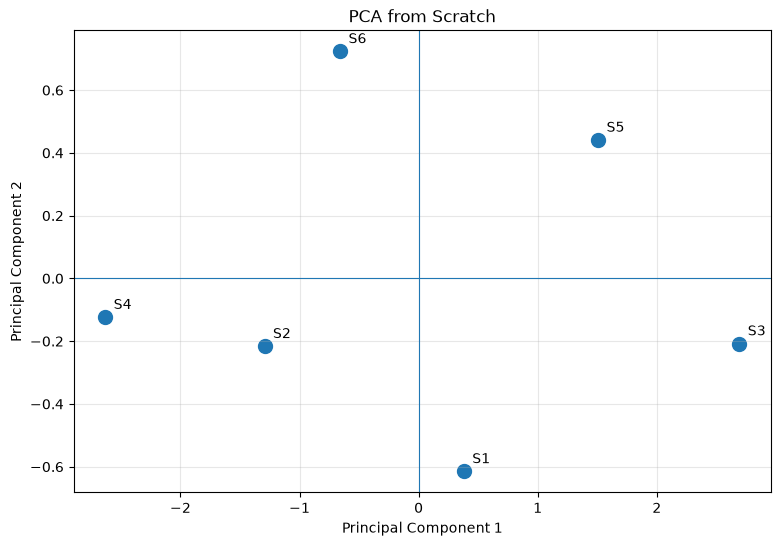

In [16]:
plt.figure(figsize=(9, 6))
plt.scatter(X_pca_scratch[:, 0], X_pca_scratch[:, 1], s=100)

for i, student in enumerate(students):
    plt.annotate(
        student,
        (X_pca_scratch[i, 0], X_pca_scratch[i, 1]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.title("PCA from Scratch")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.show()

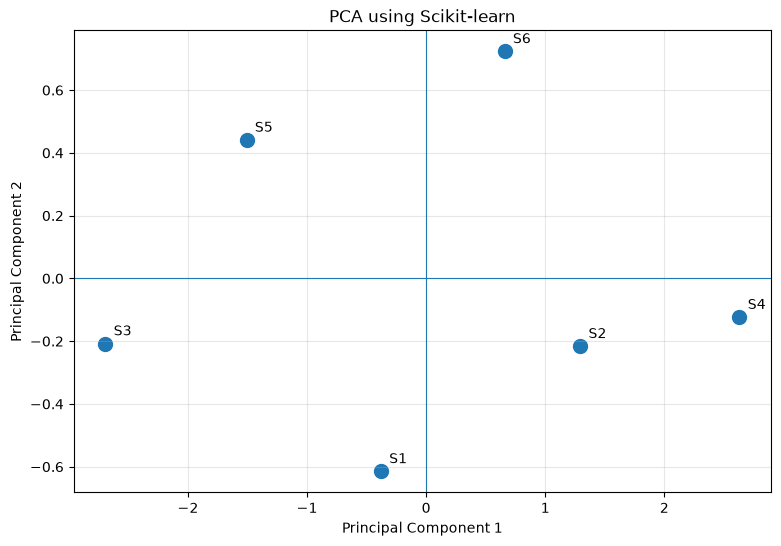

In [17]:
plt.figure(figsize=(9, 6))
plt.scatter(X_pca_sklearn[:, 0], X_pca_sklearn[:, 1], s=100)

for i, student in enumerate(students):
    plt.annotate(
        student,
        (X_pca_sklearn[i, 0], X_pca_sklearn[i, 1]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.title("PCA using Scikit-learn")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, alpha=0.3)
plt.show()

Explanation of differences : 
The two implementations should produce the same eigenvalues and explained variance ratios up to floating-point precision.

The main possible difference is a sign change. If an eigenvector is v, then -v is also a valid eigenvector. Consequently, one implementation can return coordinates with the opposite sign.

For example, if:

\(PC1_{scratch} = -PC1_{sklearn}\)

the two results are still equivalent. The orientation of the axis changed, but the PCA direction and variance explained did not.

In [18]:
pc1_percent = explained_variance_ratio_scratch[0] * 100
pc2_percent = explained_variance_ratio_scratch[1] * 100
total_percent = (explained_variance_ratio_scratch[:2].sum()) * 100

print(f"PC1 retains: {pc1_percent:.2f}%")
print(f"PC2 retains: {pc2_percent:.2f}%")
print(f"First two PCs retain: {total_percent:.2f}% of total variance")

PC1 retains: 93.49%
PC2 retains: 6.01%
First two PCs retain: 99.50% of total variance


Conclusion : The PCA implementation from scratch is consistent with Scikit-learn. The first two components provide a two-dimensional representation of the four original subjects while retaining most of the dataset's variance. Any sign difference between the two implementations is mathematically valid and does not indicate an error.

In [19]:
# Final verification
assert np.allclose(eigenvalues_sorted[:2], sklearn_eigenvalues, atol=1e-10)
assert np.allclose(
    explained_variance_ratio_scratch[:2],
    sklearn_explained_variance_ratio,
    atol=1e-10
)

for j in range(2):
    same = np.allclose(
        X_pca_scratch[:, j],
        X_pca_sklearn[:, j],
        atol=1e-10
    )
    opposite = np.allclose(
        X_pca_scratch[:, j],
        -X_pca_sklearn[:, j],
        atol=1e-10
    )
    assert same or opposite

print("✓ Eigenvalues match.")
print("✓ Explained variance ratios match.")
print("✓ Coordinates match up to possible sign changes.")
print("✓ Scratch PCA is consistent with Scikit-learn.")

✓ Eigenvalues match.
✓ Explained variance ratios match.
✓ Coordinates match up to possible sign changes.
✓ Scratch PCA is consistent with Scikit-learn.
